# Task 2 Nonlinear models

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor

## Auxiliary functions

In [2]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    label = 'SurvivalTime'
    MAX = 500

    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    df.to_csv(path, index=False)
    
def model_metrics(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Standard deviation': np.std(error)
    }
    return metrics
    
def evaluate_model(X, y, c, model, show_cmse=True, show_plot=False):
    X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, test_size=0.2, random_state=30)
    
    y_pred_cv = cross_val_predict(model, X_train, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    cMSE_test = cMSE(y_test, y_pred, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    if show_plot:
        plot_y_yhat(y_test, y_pred, plot_title="y_yhat_plot")
    
    return model, cMSE_cv, cMSE_test, model_metrics(y_test, y_pred)

## Data preprocessing

In [3]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
df = df[df['SurvivalTime'].notna()]

In [4]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

X shape: (240, 4)
y shape: (240,)
c shape: (240,)


## Task 2.1 Development

### Functions for training Polynomial and k-Nearest Neighbors

In [5]:
def train_polynomial_regression(X, y, c, degree=2):
    poly_reg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())
    
    return evaluate_model(X, y, c, poly_reg, show_cmse=False)

def train_knn_regression(X, y, c, k=5):
    knn_reg=make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    
    return evaluate_model(X, y, c, knn_reg, show_cmse=False)

### Best degree for polynomial features

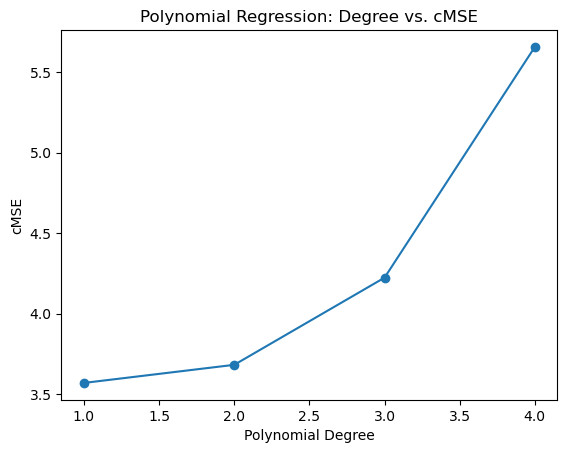

In [6]:
degrees = [1, 2, 3, 4]
poly_scores = []

for d in degrees:
    _, score, _, _ = train_polynomial_regression(X, y, c, degree=d)
    poly_scores.append(score)

plt.plot(degrees, poly_scores, marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("cMSE")
plt.title("Polynomial Regression: Degree vs. cMSE")
plt.show()

Only gets worse as the degree increases

### Best K for KNN

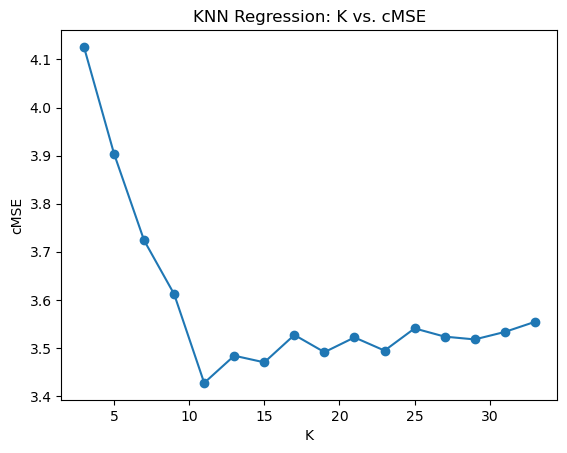

In [7]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33]
knn_scores = []

for k in k_values:
    _, score, _, _ = train_knn_regression(X, y, c, k=k)
    knn_scores.append(score)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

Best K is 11

## Task 2.2 Evaluation

### Evaluate the models developed in Task 2.1 against the baseline. Show a table with the different models and max, min, mean error, and standard deviation of the error

#### Generate metrics for each model

##### Linear regression

In [6]:
linear_reg = make_pipeline(StandardScaler(), LinearRegression())
linear_reg, cMSE_cv, cMSE_test, linear_metrics = evaluate_model(X, y, c, linear_reg)

CV cMSE: 3.568915114730242
Test cMSE: 2.947673865096783


##### Polynomial of degree 2

In [7]:
poly_reg = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                      LinearRegression())
poly_reg, cMSE_cv, cMSE_test, poly_metrics = evaluate_model(X, y, c, poly_reg)

CV cMSE: 3.681359974556493
Test cMSE: 3.325429515242577


##### KNN with K=11

In [8]:
knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=11))
knn_reg, cMSE_cv, cMSE_test, knn_metrics = evaluate_model(X, y, c, knn_reg)

CV cMSE: 3.4271491907713503
Test cMSE: 3.2974121900826447


#### Model evaluation by metrics

In [9]:
table = pd.DataFrame({
    'Linear': linear_metrics,
    'Polynomial': poly_metrics,
    'KNN': knn_metrics
})

table.T.head()


,Max Error,Min Error,Mean Error,Standard deviation
Linear,6.952703,0.004346,1.275022,1.822654
Polynomial,5.917725,0.025293,1.421378,1.928217
KNN,5.609091,0.036364,1.469697,1.948771


### Submission

Load Kaggle dataset and process it

In [10]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)

Save prediction

In [11]:
y_knn_pred = knn_reg.predict(X_kaggle_df)
save_predictions(y_knn_pred, './submissions/Nonlinear-submission-04.csv')

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [12]:
y_lr_pred = linear_reg.predict(X_kaggle_df)
save_predictions(y_lr_pred, './submissions/Nonlinear-submission-05.csv')

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
